In [1]:
#Dijkstra 算法
class Graph():
    def __init__(self, vertices):
        self.V = vertices
        self.graph = [[0 for column in range(vertices)] for row in range(vertices)]

    def printSolution(self, dist):
        print("Vertex \t Distance from Source")
        for node in range(self.V):
            print(node, "\t", dist[node])

    # 选择未处理顶点中距离最小的顶点
    def minDistance(self, dist, sptSet):
        # 初始化最小值
        min = 1e7

        # 从未处理顶点中选出距离最小的顶点
        for v in range(self.V):
            if dist[v] < min and sptSet[v] == False:
                min = dist[v]
                min_index = v

        return min_index

    # 实现Dijkstra算法
    def dijkstra(self, src):
        dist = [1e7] * self.V  # 初始时起点到所有顶点的距离为无穷大
        dist[src] = 0  # 起点到自身的距离为0
        sptSet = [False] * self.V  # 最短路径集合初始化为空

        for cout in range(self.V):
            # 步骤②：从未处理顶点中选择距离最小的顶点u
            u = self.minDistance(dist, sptSet)

            # 将顶点u加入最短路径集合
            sptSet[u] = True

            # 步骤③：更新未处理顶点的距离
            for v in range(self.V):
                if (self.graph[u][v] > 0 and sptSet[v] == False and dist[v] > dist[u] + self.graph[u][v]):
                    dist[v] = dist[u] + self.graph[u][v]

        self.printSolution(dist)
# 初始化图
g = Graph(9)
g.graph = [[0, 4, 0, 0, 0, 0, 8, 0, 0],
           [4, 0, 8, 0, 0, 0, 11, 0, 0],
           [0, 8, 0, 7, 0, 4, 0, 2, 0],
           [0, 0, 7, 0, 9, 14, 0, 0, 0],
           [0, 0, 0, 9, 0, 10, 0, 0, 0],
           [0, 0, 4, 14, 10, 0, 2, 0, 0],
           [8, 11, 0, 0, 0, 2, 0, 1, 6],
           [0, 0, 2, 0, 0, 0, 1, 0, 7],
           [0, 0, 0, 0, 0, 0, 6, 7, 0]]

# 执行Dijkstra算法
g.dijkstra(0)


Vertex 	 Distance from Source
0 	 0
1 	 4
2 	 11
3 	 18
4 	 20
5 	 10
6 	 8
7 	 9
8 	 14


In [5]:
import heapq

# 使用新的边和权重定义图
edges = {
    1: {2: 2, 3: 8, 4: 1},
    2: {1: 2, 3: 6, 5: 1},
    3: {1: 8, 2: 6, 4: 7, 5: 5, 6: 1, 7: 2},
    4: {1: 1, 3: 7, 7: 9},
    5: {2: 1, 3: 5, 6: 3, 8: 2, 9: 9},
    6: {3: 1, 5: 3, 7: 4, 9: 6},
    7: {3: 2, 4: 9, 6: 4, 9: 3, 10: 1},
    8: {5: 2, 9: 7, 11: 9},
    9: {5: 9, 6: 6, 7: 3, 8: 7, 10: 1, 11: 2},
    10: {7: 1, 9: 1, 11: 4},
    11: {8: 9, 9: 2, 10: 4}
}

def dijkstra(edges, start, end):
    # 初始化距离表，起点距离为0，其他为无穷大
    min_distance = {vertex: float('inf') for vertex in edges}
    min_distance[start] = 0
    # 优先队列，用于选取接下来要处理的点
    priority_queue = [(0, start)]
    
    while priority_queue:
        # 从队列中弹出距离最小的元素
        current_distance, current_vertex = heapq.heappop(priority_queue)
        
        # 如果当前节点是终点，返回距离
        if current_vertex == end:
            return min_distance[end]
        
        # 如果当前距离已经大于记录的最短距离，则跳过
        if current_distance > min_distance[current_vertex]:
            continue
        
        # 遍历当前节点的邻接节点
        for neighbor, weight in edges[current_vertex].items():
            distance = current_distance + weight
            
            # 如果计算的距离小于已记录的距离，更新距离并加入队列
            if distance < min_distance[neighbor]:
                min_distance[neighbor] = distance
                heapq.heappush(priority_queue, (distance, neighbor))
    
    # 如果终点不可达，返回无穷大
    return float('inf')

# 计算从顶点1到顶点11的最短路径长度
shortest_path_length = dijkstra(edges, 1, 11)
print(f"从顶点1到顶点11的最短路径长度是：{shortest_path_length}")


从顶点1到顶点11的最短路径长度是：13


最短路径矩阵为:
[0, 3, 4, 6, 7]
[11, 0, 1, 3, 9]
[10, 13, 0, 2, 8]
[8, 11, 12, 0, 6]
[2, 5, 6, 8, 0]


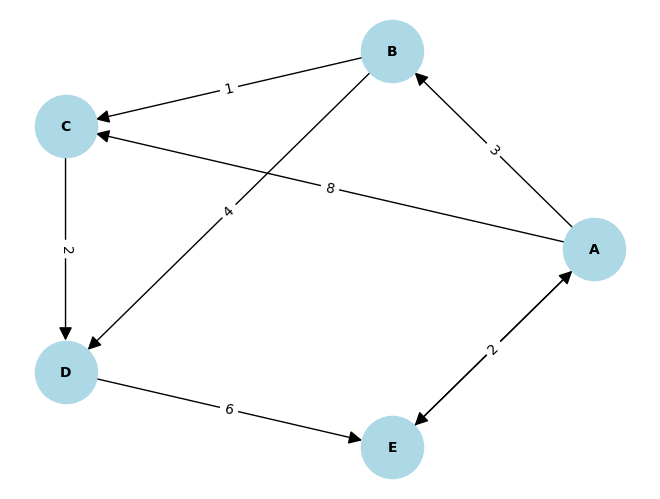

In [7]:
# 初始化城市数量
num_cities = 5

# 使用一个很大的数表示无穷大（即没有直接路径）
INF = float('inf')

# 初始化运输成本矩阵
cost_matrix = [
    [0, 3, 8, INF, 7],  
    [INF, 0, 1, 4, INF],  
    [INF, INF, 0, 2, INF],  
    [INF, INF, INF, 0, 6], 
    [2, INF, INF, INF, 0]  
]
def floyd_warshall(cost_matrix):
    # 获取城市数量
    num_cities = len(cost_matrix)
    
    # 创建一个二维数组来存储最短路径
    dist = [[cost_matrix[i][j] for j in range(num_cities)] for i in range(num_cities)]
    
    # 应用 Floyd-Warshall 算法
    for k in range(num_cities):
        for i in range(num_cities):
            for j in range(num_cities):
                # 如果通过 k 可以使 i 到 j 的路径更短，则更新路径
                if dist[i][j] > dist[i][k] + dist[k][j]:
                    dist[i][j] = dist[i][k] + dist[k][j]
    
    return dist
# 计算所有城市对之间的最短路径
shortest_paths = floyd_warshall(cost_matrix)
# 打印最短路径矩阵
print("最短路径矩阵为:")
for row in shortest_paths:
    print(row)

# 使用网络图形工具绘制运输网络
import networkx as nx
import matplotlib.pyplot as plt

# 初始化一个有向图
G = nx.DiGraph()

# 添加节点
nodes = ['A', 'B', 'C', 'D', 'E']
G.add_nodes_from(nodes)

# 添加边及其权重
edges = [
    ('A', 'B', 3), ('A', 'C', 8), ('A', 'E', 7),
    ('B', 'C', 1), ('B', 'D', 4),
    ('C', 'D', 2),
    ('D', 'E', 6),
    ('E', 'A', 2)
]

G.add_weighted_edges_from(edges)

# 绘制图形
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels=True, node_size=2000, node_color='lightblue', font_size=10, font_weight='bold', arrowsize=20)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# 显示图形
plt.show()
